# Astana Housing Market: What affects prices per m²

**Author:** Ainel Koshekova · **Data:** apartment-for-sale listings from krisha.kz, collected with `src/scraper.py`

## Why this analysis

There are common opinions that the left bank is more expensive, new builds cost more or the ground floor is cheaper. This project tests those claims on real listings and estimates how much each factor moves the price per m² once everything else is held constant.

## Questions

1. How are prices and price per m² distributed, and how wide is the spread?
2. Do districts differ in price per m², and how large is the left-bank premium?
3. How much is a newer building worth, and do monolithic, brick and panel buildings differ?
4. Is there a discount for the first and the top floor?
5. What does each factor contribute, all else equal? (hedonic regression)

## Methods

Descriptive statistics on medians (prices are heavily skewed), non-parametric tests (Kruskal–Wallis, Mann–Whitney with Holm correction), bootstrap confidence intervals for differences in medians, and OLS on log price per m² with HC3 robust standard errors.

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.clean import clean, load_raw, ERA_ORDER, LEFT_BANK
from src.stats import bootstrap_median_diff, pairwise_mannwhitney, kruskal_by, ols_hc3, design_matrix

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Palette: one accent colour, grey for everything else
ACCENT, MUTED, INK, INK_2 = "#2a78d6", "#b8b6ae", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "font.size": 10.5,
})
thousands = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

def fmt(x, d=0):
    return f"{x:,.{d}f}"

processed = ROOT / "data" / "processed" / "listings_clean.csv"
df = pd.read_csv(processed) if processed.exists() else clean(load_raw())
print(f"{len(df):,} listings, collected {df['scraped_on'].min()} – {df['scraped_on'].max()}")

Matplotlib is building the font cache; this may take a moment.


## 1. Data and data quality

Each row is one listing. These are asking not final prices, so real deals are probably a bit cheaper after bargaining.

| Feature | Meaning |
|---|---|
| `price_kzt`, `price_per_m2` | asking price and price per m², KZT |
| `rooms`, `area_m2`, `floor`, `floors_total` | parsed from the listing title |
| `district`, `bank` | one of 5 districts, and the bank of the Ishim river |
| `house_type`, `year_built`, `build_era` | building type, year built and its age group |
| `condition_group` | condition / finish, grouped into 6 categories |
| `complex_name` | residential complex, if given |

In [ ]:
cols = ["price_kzt", "area_m2", "rooms", "floor", "floors_total", "district",
        "house_type", "year_built", "condition_group", "complex_name"]
quality = pd.DataFrame({
    "filled, %": (df[cols].notna().mean() * 100).round(1),
    "unique": df[cols].nunique(),
})
quality.sort_values("filled, %")

,"filled, %",unique
condition_group,48.4,6
house_type,83.9,3
district,84.8,5
complex_name,85.4,1042
floors_total,90.9,35
floor,93.1,29
year_built,99.9,69
price_kzt,100.0,1595
area_m2,100.0,1732
rooms,100.0,8


## 2. The big picture

Most apartments are in the middle price range, but a few very expensive ones pull the average up. So I use the median instead of the mean, and a log scale for prices.

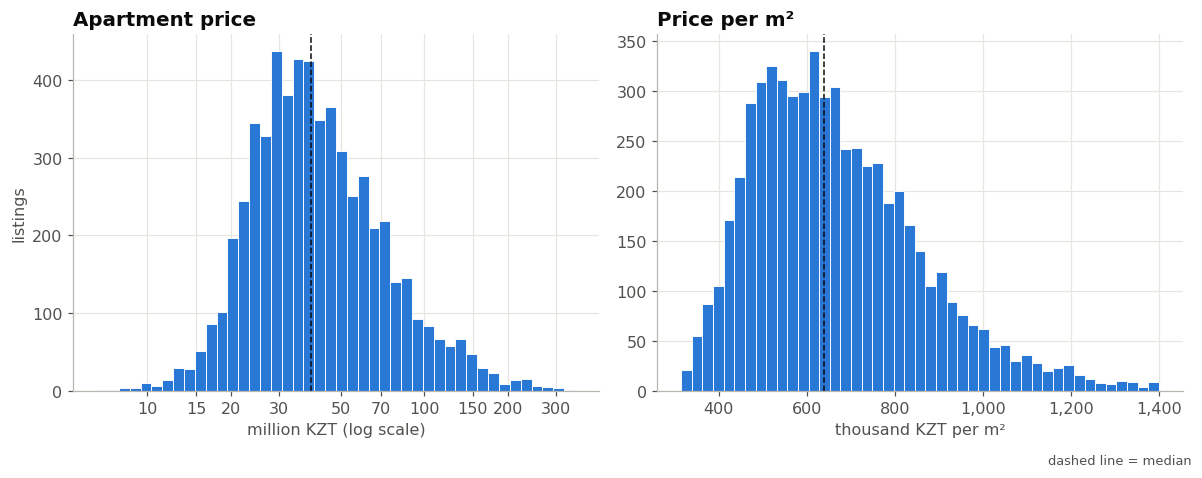

,mean,10%,25%,50%,75%,90%
price_mln,48.8,22.0,28.0,39.0,58.0,86.0
ppm_k,669.2,451.8,525.0,639.8,782.3,926.9
area_m2,71.0,38.0,44.0,63.4,87.0,115.9


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

bins = np.logspace(np.log10(df["price_mln"].min()), np.log10(df["price_mln"].max()), 45)
axes[0].hist(df["price_mln"], bins=bins, color=ACCENT, edgecolor="white", linewidth=0.6)
axes[0].set_xscale("log")
axes[0].xaxis.set_major_locator(mticker.FixedLocator([10, 15, 20, 30, 50, 70, 100, 150, 200, 300]))
axes[0].xaxis.set_minor_locator(mticker.NullLocator())
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}"))
axes[0].set(title="Apartment price", xlabel="million KZT (log scale)", ylabel="listings")
axes[0].axvline(df["price_mln"].median(), color=INK, linewidth=1, linestyle="--")

axes[1].hist(df["ppm_k"], bins=45, color=ACCENT, edgecolor="white", linewidth=0.6)
axes[1].set(title="Price per m²", xlabel="thousand KZT per m²")
axes[1].axvline(df["ppm_k"].median(), color=INK, linewidth=1, linestyle="--")
axes[1].xaxis.set_major_formatter(thousands)
fig.text(0.99, -0.02, "dashed line = median", ha="right", fontsize=8.5, color=INK_2)
fig.tight_layout(); save(fig, "01_distributions"); plt.show()

summary = df[["price_mln", "ppm_k", "area_m2"]].describe(percentiles=[.1, .25, .5, .75, .9]).T
summary[["mean", "10%", "25%", "50%", "75%", "90%"]].round(1)

## 3. Districts

Kruskal–Wallis answers "is there any difference at all", ε² says how large it is, and pairwise tests with Holm correction show which districts differ.

In [ ]:
d = df.dropna(subset=["district"])
by_district = (d.groupby("district")
                .agg(n=("ppm_k", "size"), median_ppm_k=("ppm_k", "median"),
                     q25=("ppm_k", lambda s: s.quantile(.25)), q75=("ppm_k", lambda s: s.quantile(.75)),
                     median_price_mln=("price_mln", "median"), median_area=("area_m2", "median"))
                .sort_values("median_ppm_k", ascending=False).round(1))
by_district

,n,median_ppm_k,q25,q75,median_price_mln,median_area
district,,,,,,
Esil,1692,746.1,624.2,866.7,48.9,69.5
Nura,1724,675.0,577.4,801.6,40.0,62.8
Almaty,835,536.9,465.8,631.6,32.0,63.0
Saryarka,540,497.5,441.5,565.2,26.8,51.6
Baikonur,207,486.7,438.9,564.4,32.3,63.0


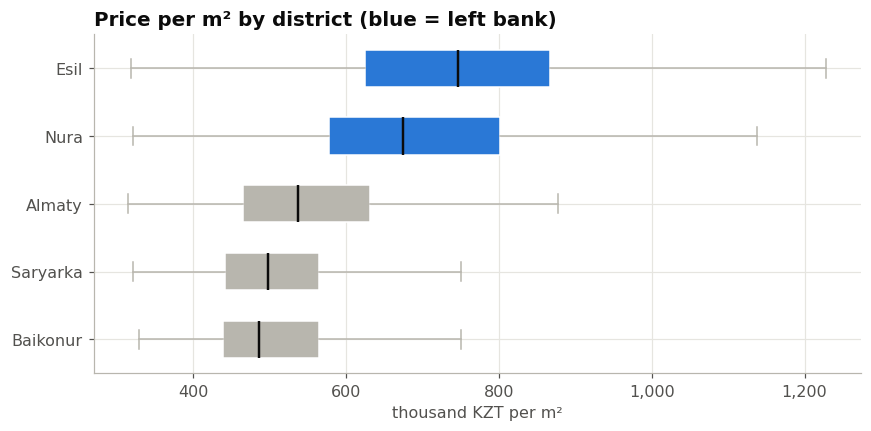

Kruskal–Wallis: H = 1383.0, p = 3.3e-298, ε² = 0.276


,group_1,group_2,median_1,median_2,effect_r,p,p_holm
0,Esil,Saryarka,746.093,497.543,0.777,0.000,0.000
1,Almaty,Esil,536.923,746.093,-0.602,0.000,0.000
2,Nura,Saryarka,675.000,497.543,0.661,0.000,0.000
3,Almaty,Nura,536.923,675.000,-0.467,0.000,0.000
4,Baikonur,Esil,486.667,746.093,-0.796,0.000,0.000
5,Baikonur,Nura,486.667,675.000,-0.682,0.000,0.000
6,Esil,Nura,746.093,675.000,0.191,0.000,0.000
7,Almaty,Saryarka,536.923,497.543,0.208,0.000,0.000
8,Almaty,Baikonur,536.923,486.667,0.240,0.000,0.000
9,Baikonur,Saryarka,486.667,497.543,-0.036,0.441,0.441


In [ ]:
order = by_district.index[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
box = ax.boxplot([d.loc[d["district"] == k, "ppm_k"] for k in order], vert=False, widths=0.55,
                 showfliers=False, patch_artist=True, tick_labels=order,
                 medianprops=dict(color=INK, linewidth=1.6), whiskerprops=dict(color=MUTED),
                 capprops=dict(color=MUTED), boxprops=dict(edgecolor="white"))
for patch, k in zip(box["boxes"], order):
    patch.set_facecolor(ACCENT if k in LEFT_BANK else MUTED)
ax.set(title="Price per m² by district (blue = left bank)", xlabel="thousand KZT per m²")
ax.xaxis.set_major_formatter(thousands)
save(fig, "02_districts"); plt.show()

kw = kruskal_by(d, "ppm_k", "district")
print(f"Kruskal–Wallis: H = {kw['H']:.1f}, p = {kw['p']:.2g}, ε² = {kw['epsilon_sq']:.3f}")
pairwise_mannwhitney(d, "ppm_k", "district").round(3)

Not surprising that Esil is the most expensive, because most new residential complexes and the new city center are there. What I didn't expect is how close Saryarka and Baikonur are, with almost the same median.

### The left-bank premium

I show the difference in medians with a 95% interval. If the interval doesn't include zero, the difference is real and not just noise

In [ ]:
left = d.loc[d["bank"] == "left", "ppm_k"]
right = d.loc[d["bank"] == "right", "ppm_k"]
bank = bootstrap_median_diff(left, right)
print(f"Median, left bank:  {fmt(left.median())}k KZT/m² (n={len(left):,})")
print(f"Median, right bank: {fmt(right.median())}k KZT/m² (n={len(right):,})")
print(f"Premium: {fmt(bank['diff'])}k KZT/m² [{fmt(bank['ci_low'])}; {fmt(bank['ci_high'])}], "
      f"or {bank['rel_diff']:+.1%}")

Median, left bank:  710k KZT/m² (n=3,416)
Median, right bank: 512k KZT/m² (n=1,582)
Premium: 198k KZT/m² [186; 208], or +38.7%


## 4. Building age and type

New buildings are mostly on the left bank, so "new" and "left bank" are mixed together. Each cell is one district and one building period. Cells with fewer than 10 listings are hidden.

,n,median_ppm_k
build_era,,
before 1990,148,459.4
1990–2004,115,472.2
2005–2014,824,511.9
2015 and newer,2465,666.7
new build (≤2 years / under construction),2338,692.2


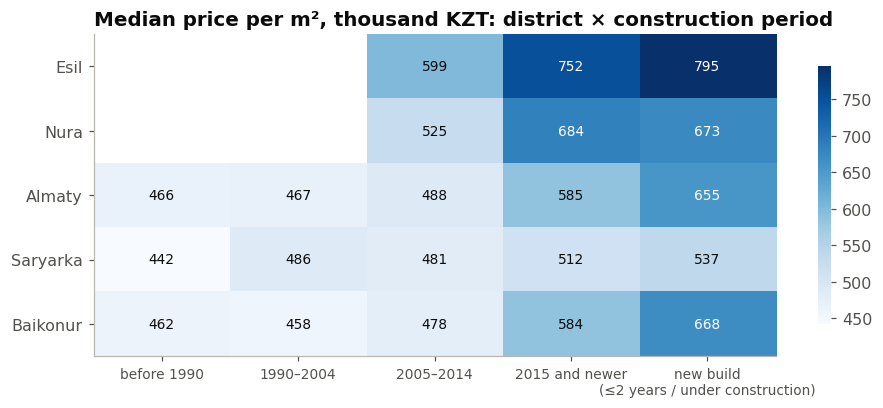

In [ ]:
era_order = [e for e in ERA_ORDER if e in set(df["build_era"].dropna())]

by_era = (df.groupby("build_era")["ppm_k"].agg(["size", "median"])
            .reindex(era_order).rename(columns={"size": "n", "median": "median_ppm_k"}).round(1))
display(by_era)

pivot = d.pivot_table(index="district", columns="build_era", values="ppm_k", aggfunc="median").reindex(columns=era_order)
counts = d.pivot_table(index="district", columns="build_era", values="ppm_k", aggfunc="size").reindex(columns=era_order)
pivot = pivot.where(counts >= 10).loc[by_district.index]

fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(pivot.to_numpy(float), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(era_order)), [e.replace(" (", "\n(") for e in era_order], fontsize=9)
ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.grid(False)
vmin, vmax = np.nanmin(pivot.to_numpy(float)), np.nanmax(pivot.to_numpy(float))
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, fmt(v), ha="center", va="center", fontsize=9,
                    color="white" if (v - vmin) / (vmax - vmin + 1e-9) > 0.55 else INK)
ax.set_title("Median price per m², thousand KZT: district × construction period")
fig.colorbar(im, ax=ax, shrink=0.8).outline.set_visible(False)
save(fig, "03_district_x_era"); plt.show()

Buildings from 2005–2014 are the cheapest, even cheaper than Soviet ones. My guess is that many of them were built fast during the 2000s boom and now feel outdated, while Soviet buildings are often in central, established areas. It's just a hypothesis.

In [ ]:
h = df.dropna(subset=["house_type"])
display(h.groupby("house_type")["ppm_k"].agg(n="size", median="median").sort_values("median", ascending=False).round(1))
kw_h = kruskal_by(h, "ppm_k", "house_type")
print(f"Kruskal–Wallis by building type: p = {kw_h['p']:.2g}, ε² = {kw_h['epsilon_sq']:.3f}")

,n,median
house_type,,
monolithic,2820,672.9
brick,1970,591.4
panel,155,485.3


Kruskal–Wallis by building type: p = 1.2e-89, ε² = 0.082


## 5. Floor

First and top floors compared with middle floors. They ignore that, for example, ground-floor apartments are more often in older buildings. Section 8 estimates the clean effect

In [ ]:
f = df.dropna(subset=["floor_cat"])
middle = f.loc[f["floor_cat"] == "middle", "ppm_k"]
rows = []
for cat in ["first", "top"]:
    r = bootstrap_median_diff(f.loc[f["floor_cat"] == cat, "ppm_k"], middle)
    rows.append({"floor": cat, "n": int((f["floor_cat"] == cat).sum()),
                 "median diff, k KZT/m²": round(r["diff"], 1),
                 "95% CI": f"[{r['ci_low']:.0f}; {r['ci_high']:.0f}]", "relative": f"{r['rel_diff']:+.1%}"})
pd.DataFrame(rows)

,floor,n,"median diff, k KZT/m²",95% CI,relative
0,first,206,-111.3,[-141; -79],-17.1%
1,top,549,-69.6,[-91; -50],-10.7%


## 6. Size and number of rooms

The line is the median price per m² in each size bin.

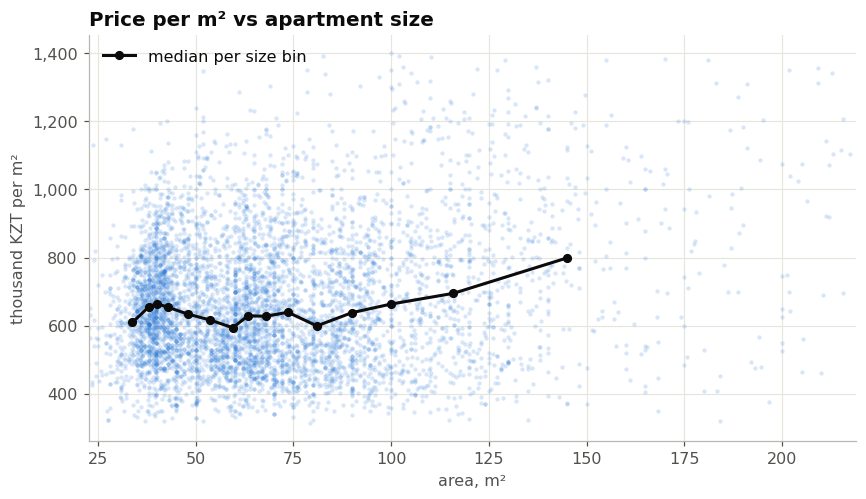

,n,median_ppm_k,median_price_mln,median_area
rooms_cat,,,,
1,1302,616.7,24.0,39.0
2,2243,639.5,35.5,58.0
3,1751,642.3,54.7,86.7
4+,599,730.8,93.5,128.5


In [ ]:
fig, ax = plt.subplots()
ax.scatter(df["area_m2"], df["ppm_k"], s=8, color=ACCENT, alpha=0.18, linewidths=0)
edges = np.quantile(df["area_m2"], np.linspace(0, 1, 16))
mid = df.groupby(pd.cut(df["area_m2"], edges, include_lowest=True), observed=True).agg(
    area=("area_m2", "median"), ppm=("ppm_k", "median"))
ax.plot(mid["area"], mid["ppm"], color=INK, linewidth=2, marker="o", markersize=5, label="median per size bin")
ax.set(title="Price per m² vs apartment size", xlabel="area, m²", ylabel="thousand KZT per m²",
       xlim=(df["area_m2"].quantile(.005), df["area_m2"].quantile(.995)))
ax.yaxis.set_major_formatter(thousands); ax.legend(frameon=False)
save(fig, "04_area_vs_ppm"); plt.show()

df.groupby("rooms_cat").agg(n=("ppm_k", "size"), median_ppm_k=("ppm_k", "median"),
                            median_price_mln=("price_mln", "median"), median_area=("area_m2", "median")).round(1)

## 7. Condition and finish

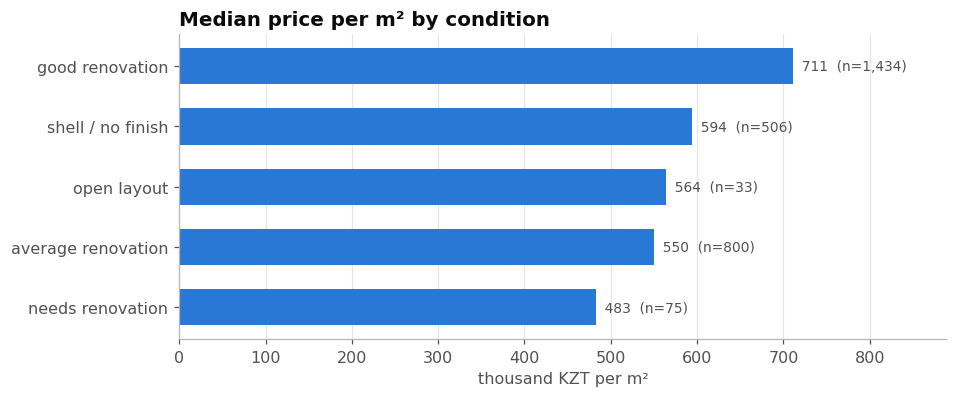

In [ ]:
c = (df.dropna(subset=["condition_group"]).groupby("condition_group")["ppm_k"]
       .agg(n="size", median="median").query("n >= 20").sort_values("median"))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(c.index, c["median"], color=ACCENT, height=0.6)
for y, (m, n) in enumerate(zip(c["median"], c["n"])):
    ax.text(m, y, f"  {fmt(m)}  (n={n:,})", va="center", fontsize=9, color=INK_2)
ax.set(title="Median price per m² by condition", xlabel="thousand KZT per m²")
ax.xaxis.set_major_formatter(thousands); ax.grid(axis="y", visible=False)
ax.set_xlim(0, c["median"].max() * 1.25)
save(fig, "05_condition"); plt.show()

### Most expensive and most affordable residential complexes

Only complexes with at least 10 listings in the sample. in others the median is too noisy.

In [ ]:
jk = (df.dropna(subset=["complex_name"]).groupby("complex_name")
        .agg(n=("ppm_k", "size"), median_ppm_k=("ppm_k", "median"),
             district=("district", lambda s: s.mode().iat[0] if s.notna().any() else None))
        .query("n >= 10").sort_values("median_ppm_k"))
print(f"Complexes with ≥10 listings: {len(jk)}")
pd.concat({"most affordable": jk.head(10), "most expensive": jk.tail(10)[::-1]}).round(1)

Complexes with ≥10 listings: 135


n  median_ppm_k  district
                complex_name                                             
most affordable KHAN RESIDENCE                 15         350.0  Saryarka
                3 гектара                      10         444.8    Almaty
                Амирель                        17         449.0      None
                Imran                          14         450.4    Almaty
                Достар-2                       13         463.8    Almaty
                По Тлендиева                   13         466.7  Saryarka
                Cosmic City                    10         474.8      Nura
                Beles Park                     11         480.0      None
                Akan City                      10         480.0  Saryarka
                Madrid 3                       13         481.5      Nura
most expensive  GreenLine.Headliner Exclusive  13        1211.5      Nura
                Family Gardens                 21        1181.0      Esil
                GreenLine. Prima               21        1175.0      Nura
                Nexpo Trend                    13        1156.5      Esil
                Atlant                         15        1121.0      Esil
                Atlant Unique                  10        1099.1      Esil
                Nexpo Aura                     20        1080.0      Esil
                Evolution                      26        1055.0      Nura
                Greenline. Tiara               14         992.0      Nura
                Qasteev                        24         979.5      Nura

## 8. Hedonic model: each factor's contribution, all else equal

The price per m² is decomposed into contributions of the apartment's characteristics:

$$\ln(\text{price per m}^2) = \beta_0 + \beta_1 \ln(\text{area}) + \sum_k \gamma_k\,\text{district}_k + \sum_m \delta_m\,\text{era}_m + \dots + \varepsilon$$

For a dummy variable, the coefficient $\gamma$ means an apartment in district $k$ costs $e^{\gamma}-1$ percent more than in the base district **with the same** size, building age, building type, floor and finish. Standard errors are HC3 because price variance grows with price (heteroskedasticity).

In [ ]:
m = df.dropna(subset=["district", "floor_cat"]).copy()
for col in ["house_type", "build_era", "condition_group"]:
    m[col] = m[col].fillna("not specified")
m["log_area"] = np.log(m["area_m2"])

def base_of(col, prefer=None):
    return prefer if prefer in set(m[col]) else m[col].mode().iat[0]

cats = {
    "district": base_of("district", "Almaty"),
    "build_era": base_of("build_era", "2015 and newer"),
    "house_type": base_of("house_type", "monolithic"),
    "floor_cat": base_of("floor_cat", "middle"),
    "condition_group": base_of("condition_group"),
}
X = design_matrix(m, ["log_area"], cats)
res = ols_hc3(m["log_ppm"], X)
res["effect, %"] = (np.exp(res["coef"]) - 1) * 100
print(f"n = {res.attrs['n']:,}, R² = {res.attrs['r2']:.3f}, adjusted R² = {res.attrs['adj_r2']:.3f}")
print("Base categories:", ", ".join(f"{k} = {v}" for k, v in cats.items()))
res.drop(index="const")[["coef", "se_hc3", "p", "effect, %"]].round(3)

n = 4,632, R² = 0.412, adjusted R² = 0.409
Base categories: district = Almaty, build_era = 2015 and newer, house_type = monolithic, floor_cat = middle, condition_group = not specified


,coef,se_hc3,p,"effect, %"
log_area,0.047,0.009,0.000,4.860
district: Baikonur,-0.033,0.015,0.027,-3.252
district: Esil,0.196,0.011,0.000,21.669
district: Nura,0.106,0.011,0.000,11.157
district: Saryarka,-0.048,0.011,0.000,-4.680
build_era: 1990–2004,-0.168,0.019,0.000,-15.457
build_era: 2005–2014,-0.183,0.009,0.000,-16.723
build_era: before 1990,-0.157,0.020,0.000,-14.509
build_era: new build (≤2 years / under construction),0.059,0.009,0.000,6.045
build_era: not specified,-0.267,0.053,0.000,-23.462


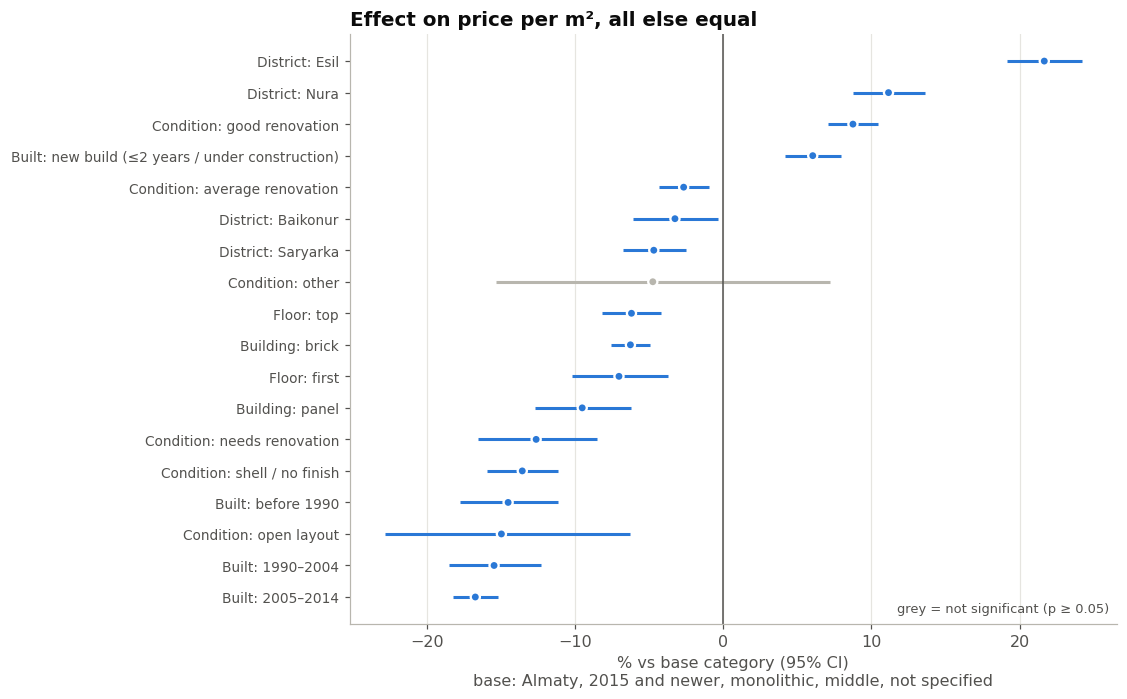

In [ ]:
eff = res.drop(index=["const", "log_area"]).copy()
eff = eff[~eff.index.str.contains("not specified")]
eff["lo"], eff["hi"] = (np.exp(eff["ci_low"]) - 1) * 100, (np.exp(eff["ci_high"]) - 1) * 100
eff = eff.sort_values("effect, %")
LABELS = {"district": "District", "build_era": "Built", "house_type": "Building",
          "floor_cat": "Floor", "condition_group": "Condition"}
eff.index = [f"{LABELS[k.split(': ')[0]]}: {k.split(': ', 1)[1]}" for k in eff.index]

fig, ax = plt.subplots(figsize=(9, 0.32 * len(eff) + 1.2))
y = np.arange(len(eff))
sig = eff["p"] < 0.05
ax.hlines(y, eff["lo"], eff["hi"], color=np.where(sig, ACCENT, MUTED), linewidth=2)
ax.scatter(eff["effect, %"], y, s=36, color=np.where(sig, ACCENT, MUTED), zorder=3,
           edgecolor="white", linewidth=1.5)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(y, eff.index, fontsize=9)
ax.set(title="Effect on price per m², all else equal",
       xlabel="% vs base category (95% CI)\nbase: " + ", ".join(cats.values()))
ax.grid(axis="y", visible=False)
ax.text(0.99, 0.02, "grey = not significant (p ≥ 0.05)", transform=ax.transAxes, ha="right", fontsize=8.5, color=INK_2)
save(fig, "06_hedonic_effects"); plt.show()

This was the most interesting part for me. Esil's premium drops from 39% to 22% once building age and condition are the same. So a big part of the "left bank premium" is really a new-building premium.

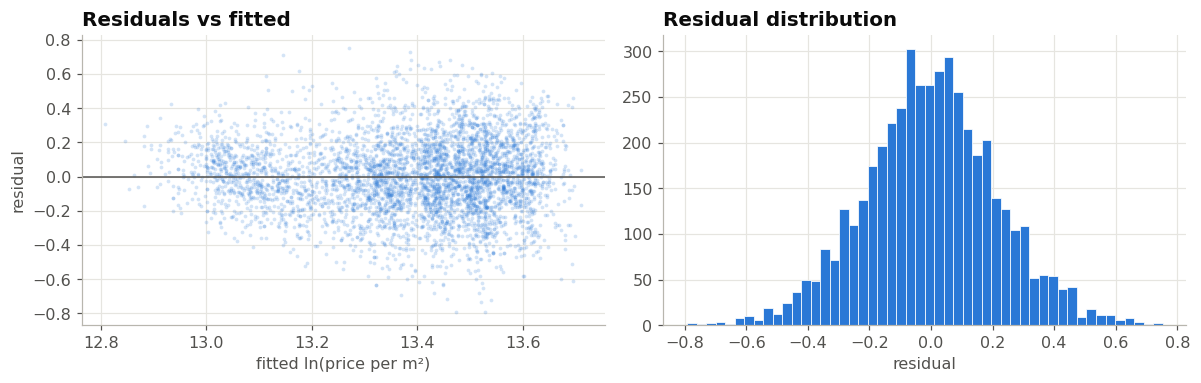

Typical prediction error: ±24% of price per m²


In [ ]:
# Model check: residuals should show no obvious structure
fitted = X.to_numpy(float) @ res["coef"].to_numpy()
resid = m["log_ppm"].to_numpy() - fitted
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].scatter(fitted, resid, s=6, alpha=0.2, color=ACCENT, linewidths=0)
axes[0].axhline(0, color=INK_2, linewidth=1)
axes[0].set(title="Residuals vs fitted", xlabel="fitted ln(price per m²)", ylabel="residual")
axes[1].hist(resid, bins=50, color=ACCENT, edgecolor="white", linewidth=0.5)
axes[1].set(title="Residual distribution", xlabel="residual")
fig.tight_layout(); plt.show()
print(f"Typical prediction error: ±{(np.exp(np.std(resid)) - 1):.0%} of price per m²")

## 9. Key numbers

This cell collects the main figures from the analysis; the conclusions below are based on them.

In [ ]:
def effect(name):
    return res.loc[name, "effect, %"] if name in res.index else np.nan

facts = {
    "Listings after cleaning": fmt(len(df)),
    "Median apartment price": f"{df['price_mln'].median():.1f}M KZT",
    "Median price per m²": f"{fmt(df['ppm_k'].median())}k KZT",
    "Most expensive district (median per m²)": f"{by_district.index[0]}: {fmt(by_district['median_ppm_k'].iat[0])}k KZT",
    "Most affordable district": f"{by_district.index[-1]}: {fmt(by_district['median_ppm_k'].iat[-1])}k KZT",
    "Raw left-bank premium": f"{bank['rel_diff']:+.1%}",
    "First vs middle floor (model)": f"{effect('floor_cat: first'):+.1f}%",
    "Top vs middle floor (model)": f"{effect('floor_cat: top'):+.1f}%",
    "Elasticity of price per m² w.r.t. area": f"{res.loc['log_area', 'coef']:+.2f}",
    "Model R²": f"{res.attrs['r2']:.2f}",
}
pd.Series(facts, name="value").to_frame()

,value
Listings after cleaning,"5,895"
Median apartment price,39.0M KZT
Median price per m²,640k KZT
Most expensive district (median per m²),Esil: 746k KZT
Most affordable district,Baikonur: 487k KZT
Raw left-bank premium,+38.7%
First vs middle floor (model),-7.0%
Top vs middle floor (model),-6.2%
Elasticity of price per m² w.r.t. area,+0.05
Model R²,0.41


## 10. Conclusions

1. **Districts.** Esil is the most expensive district (median 746k KZT per m²), Baikonur is the cheapest (487k). That's a 53% difference. District alone explains about a quarter of the variation in prices (ε² = 0.28).

2. **The left bank is expensive partly because of newer buildings.** Without any controls, Esil costs 39% more per m² than Almaty district, and Nura 26% more. When I compare apartments with the same building age, type, floor, condition and size, the gap drops to 21.7% for Esil and 11.2% for Nura. So a big part of the "left bank premium" comes from the buildings, not only from the location.

3. **Building age.** Buildings from 2005–2014 are the cheapest (16.7% below 2015+ buildings), about the same as Soviet ones (−14.5%). New builds cost 6% more than 2015+ buildings.

4. **Building type.** Monolithic buildings are valued the most. Brick is 6.3% cheaper and panel is 9.5% cheaper.

5. **Floor.** The first floor is 7% cheaper than a middle floor, the top floor is 6% cheaper.

6. **Size.** Bigger apartments are slightly more expensive per m², not cheaper as I expected (+0.5% per m² for every 10% more area). Maybe because big apartments are more common in premium complexes.

7. **Model.** The model explains 41% of the variation (R² = 0.41). The rest is probably the exact location, the specific complex and quality, which listings don't show.

**In practice:** in the same district, a new building costs about 27% more per m² than a similar 2005–2014 one. If you want the left bank but cheaper, older left-bank buildings are worth a look.

## Limitations

- These are asking prices, not final sale prices.
- It's one snapshot (October 2026), so no price changes over time.
- Overpriced listings stay on the site longer, so there are probably more of them in the data than on the real market.
- No exact coordinates, view, parking, etc.

## Next steps

- Collect the data again in 1–3 months to see how prices change.
- Add coordinates and distance to the city center.
- Try a prediction model (for example gradient boosting) and compare it with the regression.